# Milestone 4 - Training improvements: 

| Option | What it does | Why |
|---|---|---|
| `epochs` | training length | the 20-epoch run was still improving slowly (raw B 0.637 at epoch 12, 0.663 at epoch 20) |
| `sched="cosine"` / `"plateau"` | cosine decay to a floor, or halve the learning rate when the smoothed validation objective stops improving | plateau + early stopping lets the data decide how long to train |
| `es_patience`, `min_epochs`, `smooth` | early stopping on a 3-epoch average of the objective | validation scores jump by about 0.01 between epochs, so a single epoch is too noisy to stop on |
| `ema_decay` | evaluate and save an exponential moving average of the weights | smoother, usually slightly better weights at no extra training cost |
| `oversample_power` | sample images with rare defects (a, b, d) more often, weight = (largest class frequency / class frequency)^power | class imbalance: defects a and b have the lowest recall and Dice |
| `dice_weight`, `cls_weight` | loss mixing | tuned by the sweep |
| `encoder` | `resnet34`, `resnet50` or `resnext50_32x4d` (ImageNet weights) | candidate for the third model |
| `channels_last` | memory layout for tensor cores | may speed up epochs on a T4; check the epoch time |

**Selection objective** (checkpoints, scheduling, early stopping): reading **B with the classification head as a gate at 0.5** (`B_gate`). It is a cheap proxy for the final tuned pipeline, where per-class gates are tuned in the analysis notebook.

## 0. Setup

In [1]:
import os, glob, math, random, time, copy
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True            # fixed input size, so this is safe and often faster
print("PyTorch", torch.__version__, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "(turn the GPU on!)")

IMG_H, IMG_W = 128, 800
CANVAS_PIXELS = IMG_H * IMG_W
DEFECTS = ["defect_a", "defect_b", "defect_c", "defect_d"]
IMG_MEAN, IMG_STD = 0.3314, 0.1892
OUT_DIR = "/kaggle/working"
DEBUG = False                                     # True: tiny subset, 1 epoch, to test the notebook quickly

CFG = dict(run_name="m4-r34-cos40", encoder="resnet34", pretrained=True, epochs=40, batch_size=16,
           lr_decoder=1e-3, lr_encoder=3e-4, weight_decay=1e-4, warmup_epochs=1, min_lr_frac=0.02,
           sched="cosine", lr_patience=3, es_patience=None, min_epochs=20, smooth=3,
           cls_weight=0.5, dice_weight=1.0, dice_eps=1.0, oversample_power=0.0, ema_decay=0.999,
           amp=True, clip_norm=5.0, num_workers=4, seed=42, channels_last=False)
if DEBUG:
    CFG.update(epochs=1, run_name="debug")
print(CFG)

PyTorch 2.11.0+cu128 | device: cuda Tesla T4
{'run_name': 'm4-r34-cos40', 'encoder': 'resnet34', 'pretrained': True, 'epochs': 40, 'batch_size': 16, 'lr_decoder': 0.001, 'lr_encoder': 0.0003, 'weight_decay': 0.0001, 'warmup_epochs': 1, 'min_lr_frac': 0.02, 'sched': 'cosine', 'lr_patience': 3, 'es_patience': None, 'min_epochs': 20, 'smooth': 3, 'cls_weight': 0.5, 'dice_weight': 1.0, 'dice_eps': 1.0, 'oversample_power': 0.0, 'ema_decay': 0.999, 'amp': True, 'clip_norm': 5.0, 'num_workers': 4, 'seed': 42, 'channels_last': False}


## 1. Files, split and image index

In [2]:
def find_file(name, known=None):
    if known and os.path.exists(known):
        return known
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found - attach the right input to this notebook")
    return sorted(hits)[0]

TRAIN_CSV = find_file("train.csv", "/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv")
HOLDOUT_CSV = find_file("holdout.csv", "/kaggle/input/notebooks/mruniksurya/milestone-1/holdout.csv")
long = pd.read_csv(TRAIN_CSV)
rle_table = long.pivot(index="image_id", columns="defect_type", values="mask_rle")[DEFECTS]
hold = pd.read_csv(HOLDOUT_CSV)
is_val = hold["split"].astype(str).str.lower().isin({"val", "valid", "validation", "holdout"})
val_ids = sorted(set(hold.loc[is_val, "image_id"]))
train_ids = sorted(set(rle_table.index) - set(val_ids))
assert len(val_ids) == 2279 and len(train_ids) == 9114, (len(train_ids), len(val_ids))

hits = glob.glob(f"/kaggle/input/**/{train_ids[0]}.*", recursive=True)
IMG_DIR = os.path.dirname(hits[0])
IMAGE_INDEX = {os.path.splitext(f)[0]: os.path.join(IMG_DIR, f) for f in os.listdir(IMG_DIR)}
if DEBUG:
    train_ids, val_ids = train_ids[:64], val_ids[:32]
print("train images:", len(train_ids), "| validation images:", len(val_ids))

train images: 9114 | validation images: 2279


## 2. RLE decoder and metrics (readings A and B, as before)

In [3]:
def rle_decode(rle, shape=(IMG_H, IMG_W)):
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        tok = [int(t) for t in rle.split()]
        starts = np.array(tok[0::2]) - 1
        ends = starts + np.array(tok[1::2])
        for s, e in zip(starts, ends):
            flat[max(s, 0):min(e, flat.size)] = 1
    return flat.reshape(shape, order="F")

def dice_empty_aware(inter, pred_area, gt_area):
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    denom = pred_area + gt_area
    dice = np.where(denom > 0, 2 * inter / np.maximum(denom, 1), 0.0)
    return np.where((pred_area == 0) & (gt_area == 0), 1.0, dice)

def competition_score(inter, pred_area, gt_area, canvas=CANVAS_PIXELS, weights=(0.70, 0.20, 0.10)):
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    positive = gt_area > 0
    empty = ~positive
    dice = dice_empty_aware(inter, pred_area, gt_area)
    fg = dice[positive].mean()
    fp = 1 - (pred_area[empty] / canvas).mean()
    ea = (pred_area[empty] == 0).mean()
    return {"foreground_dice": fg, "false_positive_score": fp, "empty_accuracy": ea,
            "score": weights[0] * fg + weights[1] * fp + weights[2] * ea}

def both_scores(inter, pred_area, gt_area):
    m = competition_score(np.ravel(inter), np.ravel(pred_area), np.ravel(gt_area))
    return dict(A=m["score"], B=0.7 * m["foreground_dice"] + 0.3 * m["empty_accuracy"], fg=m["foreground_dice"], ea=m["empty_accuracy"])

def auc_score(score, label):
    score, label = np.asarray(score, dtype=np.float64), np.asarray(label, dtype=bool)
    order = np.argsort(score, kind="mergesort")
    _, inv, counts = np.unique(score[order], return_inverse=True, return_counts=True)
    ranks = np.empty(len(score)); ranks[order] = (np.cumsum(counts) - (counts - 1) / 2.0)[inv]
    n1, n0 = label.sum(), (~label).sum()
    return float((ranks[label].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

## 3. Dataset and class-balanced sampling
`oversample_power = 0` keeps ordinary shuffling. Above 0, every image gets the weight of its rarest defect, `(max class frequency / class frequency) ** power` (clean images weight 1), and an epoch draws as many images as before, with replacement. With power 0.5 the weights are about 1.95 (a), 3.6 (b), 1.0 (c), 1.55 (d).

In [4]:
def augment_pair(img, masks):
    if random.random() < 0.5:
        img, masks = img[:, ::-1], masks[:, :, ::-1]
    if random.random() < 0.5:
        img, masks = img[::-1, :], masks[:, ::-1, :]
    img = np.clip(img * random.uniform(0.8, 1.2) + random.uniform(-0.1, 0.1), 0.0, 1.0)
    return img, masks

class SurfaceDataset(Dataset):
    def __init__(self, image_ids, augment=False):
        self.ids = list(image_ids)
        self.rows = rle_table.loc[self.ids, DEFECTS].values
        self.augment = augment
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        img = cv2.imread(IMAGE_INDEX[self.ids[i]], cv2.IMREAD_GRAYSCALE)
        assert img is not None and img.shape == (IMG_H, IMG_W)
        img = img.astype(np.float32) / 255.0
        masks = np.stack([rle_decode(r) for r in self.rows[i]]).astype(np.float32)
        if self.augment:
            img, masks = augment_pair(img, masks)
        img = (img - IMG_MEAN) / IMG_STD
        return (torch.from_numpy(np.ascontiguousarray(img))[None].float(), torch.from_numpy(np.ascontiguousarray(masks)))

def sample_weights(ids, power):
    pres = rle_table.loc[ids, DEFECTS].notna().values               # (n, 4) which defects each image has
    freq = pres.sum(axis=0)
    f = (freq.max() / np.maximum(freq, 1)) ** power                  # per-class factor
    return np.where(pres.any(axis=1), (pres * f).max(axis=1), 1.0)

def make_loaders(cfg):
    kw = dict(num_workers=cfg["num_workers"], pin_memory=True, persistent_workers=cfg["num_workers"] > 0)
    train_ds, val_ds = SurfaceDataset(train_ids, augment=True), SurfaceDataset(val_ids, augment=False)
    if cfg["oversample_power"] > 0:
        w = sample_weights(train_ids, cfg["oversample_power"])
        sampler = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), num_samples=len(w), replacement=True)
        train_loader = DataLoader(train_ds, batch_size=cfg["batch_size"], sampler=sampler, drop_last=True, **kw)
    else:
        train_loader = DataLoader(train_ds, batch_size=cfg["batch_size"], shuffle=True, drop_last=True, **kw)
    val_loader = DataLoader(val_ds, batch_size=cfg["batch_size"], shuffle=False, **kw)
    return train_loader, val_loader

print("sample weights, power 0.5 (a, b, c, d factors):", np.round((rle_table.loc[train_ids, DEFECTS].notna().sum().max() / rle_table.loc[train_ids, DEFECTS].notna().sum().values) ** 0.5, 2))

sample weights, power 0.5 (a, b, c, d factors): [1.95 3.62 1.   1.55]


## 4. Model: ResNet encoder + U-Net decoder + classification head
Same architecture as the Milestone-3 notebook (so its checkpoints still load) but with the encoder channel widths looked up from a table, which lets the same class use ResNet34, ResNet50 or ResNeXt50. Stem + layer1..4 channels: ResNet34 `[64, 64, 128, 256, 512]`, ResNet50 and ResNeXt50 `[64, 256, 512, 1024, 2048]`.

In [5]:
ENCODERS = {"resnet34": [64, 64, 128, 256, 512],
            "resnet50": [64, 256, 512, 1024, 2048],
            "resnext50_32x4d": [64, 256, 512, 1024, 2048]}

def make_base(name, pretrained):
    fn = getattr(torchvision.models, name)
    try:
        return fn(weights="IMAGENET1K_V1" if pretrained else None)
    except TypeError:                                    # very old torchvision
        return fn(pretrained=pretrained)

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.block(x)

class UpBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = DoubleConv(in_ch + skip_ch, out_ch)
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="nearest")
        return self.conv(torch.cat([x, skip], dim=1))

class ResNetUNet(nn.Module):
    def __init__(self, base, ch, n_classes=4):
        super().__init__()
        w = base.conv1.weight.data.sum(dim=1, keepdim=True)              # RGB filters summed -> 1 gray channel
        conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        conv1.weight.data.copy_(w)
        self.stem = nn.Sequential(conv1, base.bn1, base.relu)
        self.pool = base.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = base.layer1, base.layer2, base.layer3, base.layer4
        self.up3 = UpBlock(ch[4], ch[3], 256)
        self.up2 = UpBlock(256, ch[2], 128)
        self.up1 = UpBlock(128, ch[1], 64)
        self.up0 = UpBlock(64, ch[0], 32)
        self.final = DoubleConv(32, 16)
        self.head = nn.Conv2d(16, n_classes, kernel_size=1)
        self.cls_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(ch[4], n_classes))
    def encoder_parameters(self):
        return [p for m in (self.stem, self.layer1, self.layer2, self.layer3, self.layer4) for p in m.parameters()]
    def forward(self, x):
        e0 = self.stem(x)
        e1 = self.layer1(self.pool(e0))
        e2 = self.layer2(e1)
        e3 = self.layer3(e2)
        e4 = self.layer4(e3)
        d = self.up3(e4, e3)
        d = self.up2(d, e2)
        d = self.up1(d, e1)
        d = self.up0(d, e0)
        d = F.interpolate(d, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return self.head(self.final(d)), self.cls_head(e4)

def build_model(cfg):
    return ResNetUNet(make_base(cfg["encoder"], cfg["pretrained"]), ENCODERS[cfg["encoder"]])

class EMA:
    """Exponential moving average of all floating-point weights and BatchNorm statistics."""
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay
    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step))                   # shorter memory at the start
        for e, m in zip(self.module.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point:
                e.mul_(d).add_(m.detach(), alpha=1 - d)
            else:
                e.copy_(m)

_m = build_model(dict(CFG, pretrained=False)).to(DEVICE).eval()
with torch.no_grad():
    _s, _c = _m(torch.randn(2, 1, IMG_H, IMG_W, device=DEVICE))
print(CFG["encoder"], f"parameters: {sum(p.numel() for p in _m.parameters()):,}", "| shapes:", tuple(_s.shape), tuple(_c.shape))
assert _s.shape == (2, 4, IMG_H, IMG_W) and _c.shape == (2, 4)
del _m, _s, _c

resnet34 parameters: 24,432,072 | shapes: (2, 4, 128, 800) (2, 4)


## 5. Loss, evaluation and the training function
`train(cfg, run)` trains one model and returns the history, the best epoch and the best objective. Per epoch it logs train and validation loss, readings A and B (raw and classification-gated), the classification AUC and the learning rate. It evaluates the EMA weights when `ema_decay` is set.

Learning rate per step: linear warm-up for `warmup_epochs`, then either cosine decay to `min_lr_frac` of the base rate, or (plateau) a factor that halves whenever the smoothed objective has not improved for `lr_patience` epochs. **Early stopping:** if `es_patience` is set and at least `min_epochs` are done, training stops once the smoothed objective has not improved for `es_patience` epochs.

In [6]:
USE_AMP = DEVICE.type == "cuda"
def autocast(enabled):
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=enabled and USE_AMP)

def dice_loss_on_positives(logits, targets, eps):
    probs = torch.sigmoid(logits)
    inter = (probs * targets).sum((2, 3))
    denom = probs.sum((2, 3)) + targets.sum((2, 3))
    dice = (2 * inter + eps) / (denom + eps)
    pos = targets.sum((2, 3)) > 0
    return (1 - dice[pos]).mean() if pos.any() else logits.sum() * 0.0

def make_loss(cfg):
    def loss_fn(seg, cls, y, pres):
        seg_loss = F.binary_cross_entropy_with_logits(seg, y) + cfg["dice_weight"] * dice_loss_on_positives(seg, y, cfg["dice_eps"])
        return seg_loss + cfg["cls_weight"] * F.binary_cross_entropy_with_logits(cls, pres)
    return loss_fn

def to_dev(x, cfg):
    x = x.to(DEVICE, non_blocking=True)
    return x.contiguous(memory_format=torch.channels_last) if cfg["channels_last"] else x

@torch.no_grad()
def evaluate(model, loader, loss_fn, cfg, taus=(0.5,)):
    model.eval()
    loss_sum, n = 0.0, 0
    I, PA, G, CP = {t: [] for t in taus}, {t: [] for t in taus}, [], []
    for x, y in loader:
        x, y = to_dev(x, cfg), y.to(DEVICE, non_blocking=True)
        pres = (y.sum((2, 3)) > 0).float()
        with autocast(cfg["amp"]):
            seg, cls = model(x)
        seg, cls = seg.float(), cls.float()
        loss_sum += loss_fn(seg, cls, y, pres).item() * x.size(0); n += x.size(0)
        probs, gt = torch.sigmoid(seg), y > 0.5
        G.append(gt.sum((2, 3)).cpu().numpy()); CP.append(torch.sigmoid(cls).cpu().numpy())
        for t in taus:
            pred = probs > t
            I[t].append((pred & gt).sum((2, 3)).cpu().numpy()); PA[t].append(pred.sum((2, 3)).cpu().numpy())
    return dict(loss=loss_sum / n, gt=np.concatenate(G), cls=np.concatenate(CP),
                inter={t: np.concatenate(I[t]) for t in taus}, pa={t: np.concatenate(PA[t]) for t in taus})

def summarize(res, tau=0.5, cls_gate=0.5):
    it, pa, gt = res["inter"][tau], res["pa"][tau], res["gt"]
    raw = both_scores(it, pa, gt)
    keep = res["cls"] >= cls_gate
    gated = both_scores(np.where(keep, it, 0), np.where(keep, pa, 0), gt)
    return raw, gated, [auc_score(res["cls"][:, k], gt[:, k] > 0) for k in range(4)]

def train(cfg, run=None):
    seed_everything(cfg["seed"])
    train_loader, val_loader = make_loaders(cfg)
    model = build_model(cfg).to(DEVICE)
    if cfg["channels_last"]:
        model = model.to(memory_format=torch.channels_last)
    enc_ids = {id(p) for p in model.encoder_parameters()}
    dec_params = [p for p in model.parameters() if id(p) not in enc_ids]
    base_lrs = [cfg["lr_encoder"], cfg["lr_decoder"]]
    opt = torch.optim.AdamW([dict(params=model.encoder_parameters(), lr=base_lrs[0]), dict(params=dec_params, lr=base_lrs[1])],
                            weight_decay=cfg["weight_decay"])
    ema = EMA(model, cfg["ema_decay"]) if cfg["ema_decay"] else None
    eval_model = ema.module if ema else model
    loss_fn = make_loss(cfg)
    use_amp = cfg["amp"] and USE_AMP
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    except Exception:
        scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    spe = len(train_loader)
    total_steps, warm = cfg["epochs"] * spe, max(1, cfg["warmup_epochs"] * spe)
    lr_scale, step = 1.0, 0
    def factor(s):
        if s < warm:
            return (s + 1) / warm
        if cfg["sched"] == "cosine":
            p = (s - warm) / max(1, total_steps - warm)
            return cfg["min_lr_frac"] + (1 - cfg["min_lr_frac"]) * 0.5 * (1 + math.cos(math.pi * p))
        return lr_scale

    best_path, last_path = f"{OUT_DIR}/{cfg['run_name']}_best.pt", f"{OUT_DIR}/{cfg['run_name']}_last.pt"
    history, objs = [], []
    best_obj, best_epoch, best_smooth, bad_es, bad_lr = -1.0, 0, -1.0, 0, 0
    for epoch in range(1, cfg["epochs"] + 1):
        t0 = time.time()
        model.train()
        run_loss, n = 0.0, 0
        for x, y in train_loader:
            x, y = to_dev(x, cfg), y.to(DEVICE, non_blocking=True)
            pres = (y.sum((2, 3)) > 0).float()
            f = factor(step)
            for g, b in zip(opt.param_groups, base_lrs):
                g["lr"] = b * f
            opt.zero_grad(set_to_none=True)
            with autocast(cfg["amp"]):
                seg, cls = model(x)
            loss = loss_fn(seg.float(), cls.float(), y, pres)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["clip_norm"])
            scaler.step(opt); scaler.update()
            if ema:
                ema.update(model, step)
            step += 1
            run_loss += loss.item() * x.size(0); n += x.size(0)
        train_loss = run_loss / n

        res = evaluate(eval_model, val_loader, loss_fn, cfg)
        raw, gated, aucs = summarize(res)
        obj = gated["B"]
        objs.append(obj)
        row = dict(epoch=epoch, train_loss=train_loss, val_loss=res["loss"], A=raw["A"], B=raw["B"], fg=raw["fg"], ea=raw["ea"],
                   A_gate=gated["A"], B_gate=gated["B"], cls_auc=float(np.mean(aucs)), lr_dec=opt.param_groups[1]["lr"], time_s=time.time() - t0)
        history.append(row)
        if run is not None:
            run.log({"epoch": epoch, "train/loss": train_loss, "val/loss": res["loss"], "val/A@0.5": raw["A"], "val/B@0.5": raw["B"],
                     "val/fg_dice@0.5": raw["fg"], "val/empty_acc@0.5": raw["ea"], "val/A_clsgate": gated["A"], "val/B_clsgate": gated["B"],
                     "val/cls_auc_mean": row["cls_auc"], "lr_decoder": row["lr_dec"], "epoch_time_s": row["time_s"]})
        print(f"epoch {epoch:02d} | train {train_loss:.4f} | val {res['loss']:.4f} | A {raw['A']:.4f} B {raw['B']:.4f} fg {raw['fg']:.4f} ea {raw['ea']:.3f} | "
              f"gated B {gated['B']:.4f} | AUC {row['cls_auc']:.3f} | lr {row['lr_dec']:.2e} | {row['time_s']:.0f}s")
        if obj > best_obj:
            best_obj, best_epoch = obj, epoch
            torch.save(eval_model.state_dict(), best_path)                 # EMA weights if EMA is on
        smooth = float(np.mean(objs[-cfg["smooth"]:]))
        if smooth > best_smooth + 1e-4:
            best_smooth, bad_es, bad_lr = smooth, 0, 0
        else:
            bad_es += 1; bad_lr += 1
        if cfg["sched"] == "plateau" and bad_lr >= cfg["lr_patience"]:
            lr_scale = max(cfg["min_lr_frac"], lr_scale * 0.5); bad_lr = 0
            print(f"   learning-rate factor -> {lr_scale:.3f}")
        if cfg["es_patience"] and epoch >= cfg["min_epochs"] and bad_es >= cfg["es_patience"]:
            print(f"   early stopping at epoch {epoch}: no smoothed improvement for {bad_es} epochs")
            break
    torch.save(eval_model.state_dict(), last_path)
    del train_loader
    return dict(history=history, best_obj=best_obj, best_epoch=best_epoch, best_path=best_path, last_path=last_path,
                model=eval_model, loss_fn=loss_fn, val_loader=val_loader)

## 6. A single run
Edit `CFG` here for each experiment (the settings cell above holds the defaults). Suggested order of experiments:

1. `run_name="m4-r34-cos40"`, defaults (40 epochs, cosine, EMA). Compare with the 20-epoch run (raw B 0.664, gated B 0.685, foreground Dice 0.638).
2. `run_name="m4-r34-plateau-es"`, `sched="plateau"`, `epochs=80`, `es_patience=8`, `min_epochs=25`. This lets the data decide the length (roughly 2 to 3 hours at most).
3. `run_name="m4-r34-os05"`, as 1 with `oversample_power=0.5`.
Only change one thing at a time, otherwise the W&B comparison cannot say which change helped.

In [7]:
import wandb
from kaggle_secrets import UserSecretsClient
wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
run = wandb.init(entity="22f2001613-indian-institute-of-technology-madras", project="22f2001613-t32026", name=CFG["run_name"],
                 config=dict(CFG, n_train=len(train_ids), n_val=len(val_ids)), tags=["milestone-4", CFG["encoder"], CFG["sched"]])
out = train(CFG, run)
print("best epoch:", out["best_epoch"], "| best gated B:", round(out["best_obj"], 4))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 22f2001613 (22f2001613-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run 2c34p0ai
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261102_024126-2c34p0ai
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run m4-r34-cos40
wandb: ⭐️ View project at https://wandb.ai/22f2001613-indian-institute-of-technology-madras/22f2001613-t32026
wandb: 🚀 View run at https://wandb.ai/22f2001613-indian-institute-o

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 185MB/s]


epoch 01 | train 1.4384 | val 0.9916 | A 0.5823 B 0.5364 fg 0.4379 ea 0.766 | gated B 0.5411 | AUC 0.906 | lr 1.00e-03 | 158s
epoch 02 | train 0.8176 | val 0.6666 | A 0.6242 B 0.5463 fg 0.5228 ea 0.601 | gated B 0.5653 | AUC 0.924 | lr 9.98e-04 | 128s
epoch 03 | train 0.7050 | val 0.5993 | A 0.6284 B 0.5164 fg 0.5522 ea 0.433 | gated B 0.5876 | AUC 0.933 | lr 9.94e-04 | 127s
epoch 04 | train 0.6560 | val 0.5586 | A 0.6497 B 0.5456 fg 0.5760 ea 0.475 | gated B 0.5977 | AUC 0.939 | lr 9.86e-04 | 127s
epoch 05 | train 0.6283 | val 0.5456 | A 0.6580 B 0.5594 fg 0.5840 ea 0.502 | gated B 0.6093 | AUC 0.938 | lr 9.75e-04 | 127s
epoch 06 | train 0.6101 | val 0.5348 | A 0.6630 B 0.5628 fg 0.5921 ea 0.494 | gated B 0.6169 | AUC 0.939 | lr 9.61e-04 | 127s
epoch 07 | train 0.5814 | val 0.5197 | A 0.6718 B 0.5790 fg 0.5992 ea 0.532 | gated B 0.6280 | AUC 0.944 | lr 9.44e-04 | 127s
epoch 08 | train 0.5707 | val 0.5116 | A 0.6768 B 0.5852 fg 0.6055 ea 0.538 | gated B 0.6370 | AUC 0.947 | lr 9.24e-04

       train_loss  val_loss       A       B      fg      ea  A_gate  B_gate  cls_auc  lr_dec    time_s
epoch                                                                                                 
1          1.4384    0.9916  0.5823  0.5364  0.4379  0.7660  0.5440  0.5411   0.9063  0.0010  158.0222
2          0.8176    0.6666  0.6242  0.5463  0.5228  0.6010  0.5679  0.5653   0.9239  0.0010  127.5350
3          0.7050    0.5993  0.6284  0.5164  0.5522  0.4328  0.5904  0.5876   0.9329  0.0010  127.4400
4          0.6560    0.5586  0.6497  0.5456  0.5760  0.4748  0.6002  0.5977   0.9390  0.0010  127.2970
5          0.6283    0.5456  0.6580  0.5594  0.5840  0.5018  0.6120  0.6093   0.9380  0.0010  127.3184
6          0.6101    0.5348  0.6630  0.5628  0.5921  0.4945  0.6198  0.6169   0.9388  0.0010  127.2954
7          0.5814    0.5197  0.6718  0.5790  0.5992  0.5320  0.6310  0.6280   0.9440  0.0009  127.4190
8          0.5707    0.5116  0.6768  0.5852  0.6055  0.5379  0.6399  0.63

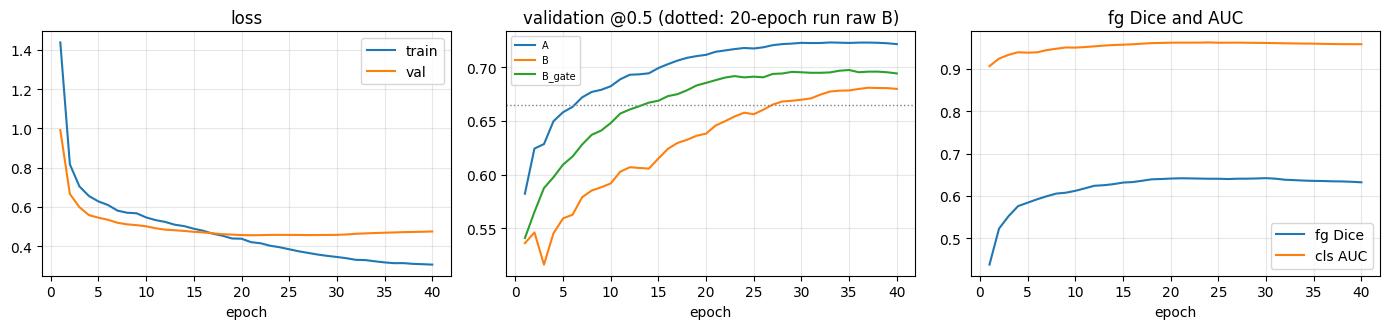

wandb: updating run metadata


 tau      A      B     fg     ea  B_clsgate
 0.3 0.7221 0.6760 0.6366 0.7679     0.6972
 0.5 0.7224 0.6782 0.6355 0.7780     0.6972
 0.7 0.7227 0.6816 0.6338 0.7930     0.6971
 0.9 0.7221 0.6872 0.6285 0.8242     0.6962
          true_pos_rate  pred_pos_rate  recall_pairs  fg_dice  empty_acc  cls_auc
cls                                                                              
defect_a          0.095          0.312         0.704    0.420      0.742    0.923
defect_b          0.028          0.281         0.810    0.466      0.737    0.967
defect_c          0.360          0.524         0.916    0.655      0.715    0.961
defect_d          0.150          0.216         0.924    0.755      0.911    0.986


wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading output.log; uploading config.yaml
wandb: 
wandb: Run history:
wandb:             epoch ▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
wandb:      epoch_time_s █▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:        lr_decoder ███████▇▇▇▇▇▆▆▆▆▅▅▅▅▄▄▄▄▃▃▃▃▂▂▂▂▂▁▁▁▁▁▁▁
wandb:        train/loss █▄▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:         val/A@0.5 ▁▃▃▄▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇████████████████████
wandb:     val/A_clsgate ▁▂▃▄▄▄▅▅▅▆▆▆▆▇▇▇▇▇▇▇████████████████████
wandb:         val/B@0.5 ▂▂▁▂▃▃▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇███████████
wandb:     val/B_clsgate ▁▂▃▄▄▄▅▅▅▆▆▆▆▇▇▇▇▇▇▇████████████████████
wandb:  val/cls_auc_mean ▁▃▄▅▅▅▆▆▇▆▇▇▇▇▇▇█████████████████████▇▇▇
wandb: val/empty_acc@0.5 █▄▁▂▂▂▃▃▃▃▄▄▄▃▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇████████
wandb:                +2 ...
wandb: 
wandb: Run summary:
wandb:      best/obj 0.69722
wandb:    best_epoch 35
wandb:         epoch 40
wandb:  epoch_time_s 127.43274
wandb:    lr_de

In [8]:
hist = pd.DataFrame(out["history"]).set_index("epoch")
print(hist.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].plot(hist.index, hist["train_loss"], label="train"); axes[0].plot(hist.index, hist["val_loss"], label="val"); axes[0].set_title("loss"); axes[0].legend()
for c in ["A", "B", "B_gate"]: axes[1].plot(hist.index, hist[c], label=c)
axes[1].axhline(0.6644, color="gray", ls=":", lw=1); axes[1].set_title("validation @0.5 (dotted: 20-epoch run raw B)"); axes[1].legend(fontsize=7)
axes[2].plot(hist.index, hist["fg"], label="fg Dice"); axes[2].plot(hist.index, hist["cls_auc"], label="cls AUC"); axes[2].set_title("fg Dice and AUC"); axes[2].legend()
for a in axes: a.set_xlabel("epoch"); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{CFG['run_name']}_curves.png", dpi=120); plt.show()
hist.to_csv(f"{OUT_DIR}/{CFG['run_name']}_history.csv")
wandb.log({"curves": wandb.Image(f"{OUT_DIR}/{CFG['run_name']}_curves.png")})

# threshold sweep and per-class view with the best checkpoint
model = out["model"]; model.load_state_dict(torch.load(out["best_path"], map_location=DEVICE))
taus = (0.3, 0.5, 0.7, 0.9)
res = evaluate(model, out["val_loader"], out["loss_fn"], CFG, taus=taus)
rows = []
for t in taus:
    raw, gated, _ = summarize(res, tau=t)
    rows.append(dict(tau=t, A=raw["A"], B=raw["B"], fg=raw["fg"], ea=raw["ea"], B_clsgate=gated["B"]))
print(pd.DataFrame(rows).round(4).to_string(index=False))
gt, pa, it, cp = res["gt"], res["pa"][0.5], res["inter"][0.5], res["cls"]
diag = []
for k, d in enumerate(DEFECTS):
    pos = gt[:, k] > 0
    diag.append(dict(cls=d, true_pos_rate=pos.mean(), pred_pos_rate=(pa[:, k] > 0).mean(), recall_pairs=(it[pos, k] > 0).mean(),
                     fg_dice=dice_empty_aware(it[pos, k], pa[pos, k], gt[pos, k]).mean(), empty_acc=(pa[~pos, k] == 0).mean(), cls_auc=auc_score(cp[:, k], pos)))
print(pd.DataFrame(diag).set_index("cls").round(3).to_string())
wandb.summary.update({"best_epoch": out["best_epoch"], "best/obj": out["best_obj"]})
wandb.finish()

## 7. Hyperparameter search with W&B Sweeps (optional, run after the single runs)
A sweep is a set of short runs, each with settings drawn from the ranges below (Bayesian search: each new trial is chosen using the results so far). Each trial trains for `SWEEP_EPOCHS` epochs with cosine decay and is scored by the best gated B. Set `RUN_SWEEP = True`, make sure the single-run cell above is not re-run in the same session, and expect about 2 minutes per epoch, i.e. `count x SWEEP_EPOCHS x 2` minutes (8 trials x 8 epochs is about 2 hours). Short runs only roughly predict long runs, so use the sweep to find a good region, then confirm with one long run.

In [9]:
RUN_SWEEP = False
SWEEP_EPOCHS, SWEEP_COUNT = 8, 8

sweep_config = dict(
    method="bayes", metric=dict(name="best/obj", goal="maximize"),
    parameters=dict(
        lr_decoder=dict(distribution="log_uniform_values", min=3e-4, max=3e-3),
        lr_encoder=dict(distribution="log_uniform_values", min=1e-4, max=1e-3),
        weight_decay=dict(values=[1e-5, 1e-4, 1e-3]),
        cls_weight=dict(values=[0.25, 0.5, 1.0]),
        dice_weight=dict(values=[0.5, 1.0, 2.0]),
        oversample_power=dict(values=[0.0, 0.5, 1.0])))

def sweep_run():
    r = wandb.init(entity="22f2001613-indian-institute-of-technology-madras", project="22f2001613-t32026", tags=["milestone-4", "sweep"])
    cfg = dict(CFG); cfg.update(dict(r.config))
    cfg.update(epochs=SWEEP_EPOCHS, run_name=f"sweep-{r.name}", sched="cosine", es_patience=None)
    out_ = train(cfg, r)
    r.summary.update({"best/obj": out_["best_obj"], "best/epoch": out_["best_epoch"]})
    r.log({"best/obj": out_["best_obj"]})
    r.finish()

if RUN_SWEEP:
    wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
    sweep_id = wandb.sweep(sweep_config, entity="22f2001613-indian-institute-of-technology-madras", project="22f2001613-t32026")
    wandb.agent(sweep_id, function=sweep_run, count=SWEEP_COUNT)